# Statistical Arbitrage in Cryptocurrencies - Momentum and Reversal on Live Data

**Wall Street Quants - Bootcamp Project.** This notebook reproduces every result in
`crypto_research_report.docx`, the deck and the workbook. Data run from 2021-01-01 to **2026-10-08**.

**Goal (from the brief):** research profitable momentum and/or reversal strategies in crypto, test them with
unconstrained backtests at 20 bps (market orders) / 7 bps (limit orders), combine them with a weighting
scheme, and report returns, volatility, Sharpe, max drawdown and alpha / beta.

| Brief item | Where it is tested |
|---|---|
| Momentum - time horizon | Section 3 (daily) and Section 4 (hourly) |
| Momentum - new information / activity | Section 5 |
| Momentum - seasonality | Section 6 |
| Momentum - investment themes | Section 7 |
| Momentum - technical plays | Section 4 (front-running the US session) |
| Reversal - time horizon / uninformed trading | Sections 3, 4 and 5 |
| Reversal - correlation | Section 8 (residual reversal, cointegrated pairs) |
| Reversal - macro | Section 9 (DVOL, realized vol, dispersion, correlation) |
| Execution | Section 10 |
| Weighting | Section 11 |
| Performance evaluation | Section 12 |

**Headline:** a market-neutral portfolio combining a momentum ensemble with long-horizon reversal earns a net
Sharpe of 1.02, alpha of 20.6% a year (t = 2.19) and beta to Bitcoin of
-0.02 over 2021-12-28 to 2026-10-08; its hold-out (2024 onward) Sharpe is 0.55.


## 0. Setup

In [1]:
import os, sys, json, inspect, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sys.path.insert(0, "src")

REFRESH_DATA = False   # True: download the latest prices (hourly download takes ~45 minutes)
RUN_PAIRS = True       # re-run the cointegration engine (~1 minute)

## 1. Data
Daily and hourly OHLCV from the Coinbase Exchange public API (Binance is geo-blocked here, HTTP 451) and the Deribit DVOL implied-volatility index. Set `REFRESH_DATA = True` to pull the latest data.

In [2]:
if REFRESH_DATA:
    import fetch_data
    fetch_data.fetch_daily(); fetch_data.fetch_dvol(); fetch_data.fetch_hourly()

import sa_core as C
close, rets, dollar_vol = C.load_panel()
coverage = pd.DataFrame({"first date": close.apply(lambda s: s.first_valid_index().date()),
                         "last date": close.apply(lambda s: s.last_valid_index().date()),
                         "days": close.notna().sum(),
                         "last close": close.ffill().iloc[-1]})
print(f"{close.shape[1]} coins, {close.index.min().date()} to {close.index.max().date()}")
coverage

16 coins, 2021-01-01 to 2026-10-08


,first date,last date,days,last close
asset,,,,
BTC,2021-01-01,2026-10-08,2107,"81,692.790"
ETH,2021-01-01,2026-10-08,2107,"2,472.890"
SOL,2021-06-17,2026-10-08,1940,109.540
ADA,2021-03-18,2026-10-08,2031,0.232
DOGE,2021-06-03,2026-10-08,1954,0.084
AVAX,2021-09-30,2026-10-08,1835,10.069
LINK,2021-01-01,2026-10-08,2107,12.701
LTC,2021-01-01,2026-10-08,2107,63.124
DOT,2021-06-16,2026-10-08,1941,1.089


hourly bars: 668,768  |  DVOL days: 2,026 (2021-03-24 to 2026-10-09)


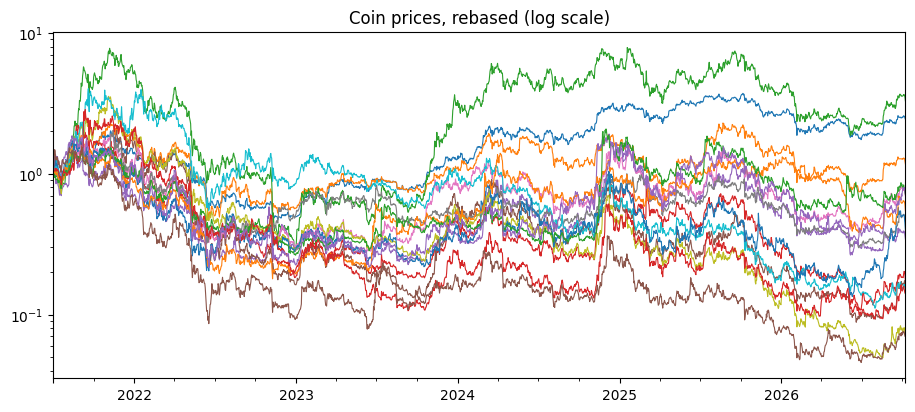

In [3]:
hourly = pd.read_csv("data/crypto_hourly.csv", usecols=["asset", "date"])
dvol = pd.read_csv("data/dvol.csv", index_col=0, parse_dates=True)
print(f"hourly bars: {len(hourly):,}  |  DVOL days: {len(dvol):,} ({dvol.index.min().date()} to {dvol.index.max().date()})")
ax = (close.loc["2021-07-01":] / close.loc["2021-07-01":].bfill().iloc[0]).plot(figsize=(11, 4.5), logy=True, legend=False, lw=0.8)
ax.set_title("Coin prices, rebased (log scale)"); plt.show()

## 2. The unconstrained backtest engine
Weights use information up to the close of day t and earn day t+1's return. Gross exposure is scaled to 1. Cost = turnover x cost per unit (20 bps market, 7 bps limit).

In [4]:
for f in [C.cs_weights, C.ts_weights, C.hold, C.band, C.backtest, C.alpha_beta]:
    print(inspect.getsource(f))

def cs_weights(signal, direction=1):
    """Cross-sectional dollar-neutral weights proportional to the demeaned
    cross-sectional rank of `signal`.  direction=+1 momentum, -1 reversal."""
    r = signal.rank(axis=1, pct=True)
    r = r.sub(r.mean(axis=1), axis=0)
    return normalise(direction * r)

def ts_weights(signal, vol=None, direction=1):
    """Time-series weights: sign of each asset's own signal, optionally
    inverse-volatility scaled, then gross-normalised."""
    w = direction * np.sign(signal)
    if vol is not None:
        w = w / vol
    return normalise(w.replace([np.inf, -np.inf], np.nan).fillna(0))

def hold(w, h):
    """Overlapping-portfolio holding period (Jegadeesh-Titman): average of the
    last h daily target portfolios.  Cuts turnover roughly by a factor h."""
    if h <= 1:
        return w
    return normalise(w.rolling(h, min_periods=1).mean())

def band(w, threshold):
    """No-trade band: only move a position when the target differs from the
    curre

## 3. Run the pipeline
The cointegration engine (`src/statarb.py`) and the research programme (`src/research.py`) write every table to `data/research/` and every chart to `figures/`.

In [5]:
if RUN_PAIRS:
    import subprocess
    out = subprocess.run([sys.executable, "src/statarb.py"], capture_output=True, text=True)
    print(out.stdout[-1500:])

4    0.127  -0.267   -0.160 -0.352  -0.096    0.126  -0.476    0.011
TS Momentum (net)                 0.033    0.076   0.433    0.640 -0.088   0.375    0.491   1.025   -0.026
CS Momentum (net)                -0.152    0.256  -0.592   -0.956 -0.663  -0.229    0.456  -1.118    0.128
Equal-Weight B&H                 -0.128    0.701  -0.182   -0.253 -0.774  -0.165    0.508   0.353    1.167
Buy & Hold BTC                    0.127    0.508   0.250    0.355 -0.670   0.189    0.494   1.066    1.001

=== run summary ===
{
  "n_assets": 16,
  "oos_start": "2022-01-01",
  "oos_end": "2026-10-08",
  "oos_days": 1742,
  "n_formation_windows": 83,
  "avg_pairs_per_window": 8.88,
  "unique_pairs_traded": 120,
  "avg_daily_turnover": 0.0325,
  "avg_active_pairs": 8.99,
  "cost_bps_per_leg": 20.0,
  "form_days": 180,
  "step_days": 21,
  "z_entry": 2.0,
  "z_exit": 0.5,
  "z_stop": 4.0
}

Most-selected pairs:
           windows_selected  pct_of_windows
LTC-AVAX                 17           0.205
XLM-A

In [6]:
import research as RS
RS.main()
S = json.load(open("data/research/summary.json"))
rd = lambda n: pd.read_csv(f"data/research/{n}.csv")

Panel 2021-01-01 -> 2026-10-08, 16 assets
A. horizon scan


A2/C/E. intraday


B. activity


D. themes


F. correlation


...

H. selection


   momentum ensemble: ['TS momentum blend H=1 + DVOL filter', 'Theme momentum L=14 H=7', 'CS momentum L=14 H=7']
   selected reversal: Long-horizon reversal L=60 skip=14 H=14


   execution chosen on IS: {'Momentum': 'No-trade band 2%', 'Reversal': 'Hold 3d (overlapping)'}


   weighting method chosen on IS: Mean-variance (shrunk)



=== Full-period performance ===
                                          Ann.Return   CAGR  Ann.Vol  Sharpe  Sortino  MaxDD  Calmar  HitRate  t-stat  Alpha   Beta  Alpha t  Turnover
Strategy                                                                                                                                              
Momentum ensemble (net 20bps market)           0.223  0.182    0.333   0.668    1.001 -0.311   0.585    0.481   1.460  0.252 -0.130    1.681     0.197
Momentum ensemble (net 7bps limit)             0.316  0.298    0.333   0.950    1.424 -0.251   1.186    0.489   2.079  0.346 -0.130    2.310       NaN
Reversal (net 7bps limit)                      0.187  0.183    0.196   0.955    1.598 -0.337   0.544    0.504   2.000  0.187  0.002    2.009     0.059
Reversal (net 20bps market)                    0.159  0.151    0.196   0.812    1.359 -0.356   0.423    0.498   1.702  0.159  0.002    1.708       NaN
Cointegration pairs (net 20bps)               -0.007 -0.009  

## 4. Time horizon - momentum vs reversal
**Daily:** crypto shows momentum from 1 to 30 days and reversal only at 60-90 days, the opposite of the equity pattern in the brief.

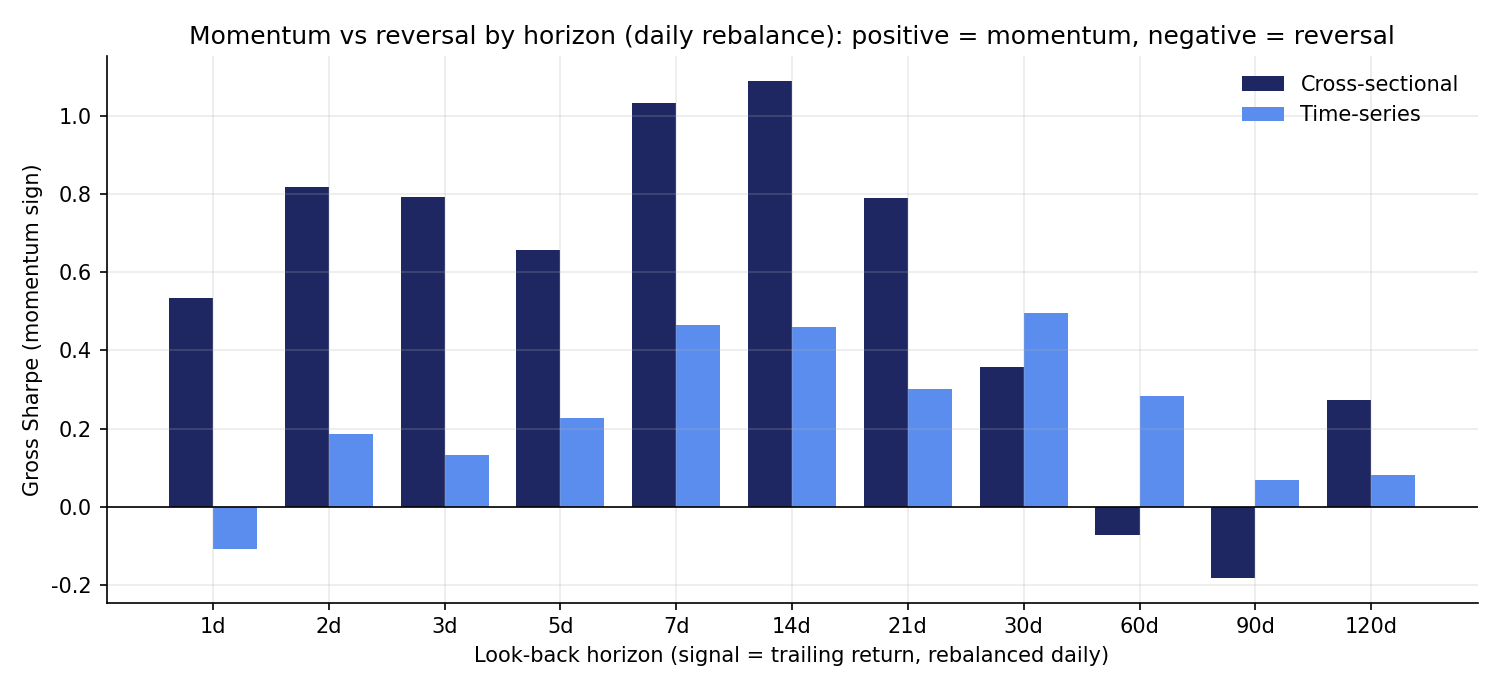

,Strategy,Gross IS,Gross OOS,Gross Full,Net20 Full,Net7 Full,Turnover
0,Cross-sectional L=1d,0.405,0.658,0.534,-3.960,-1.076,1.320
1,Time-series L=1d,-0.802,0.602,-0.110,-1.459,-0.592,1.052
2,Cross-sectional L=2d,0.644,0.990,0.819,-2.478,-0.354,0.933
3,Time-series L=2d,-0.057,0.435,0.185,-0.755,-0.149,0.705
4,Cross-sectional L=3d,0.953,0.632,0.794,-1.970,-0.186,0.769
5,Time-series L=3d,0.171,0.096,0.133,-0.633,-0.138,0.569
6,Cross-sectional L=5d,0.949,0.357,0.658,-1.530,-0.114,0.607
7,Time-series L=5d,0.086,0.368,0.226,-0.356,0.021,0.444
8,Cross-sectional L=7d,1.374,0.697,1.033,-0.783,0.393,0.513
9,Time-series L=7d,0.687,0.245,0.466,-0.026,0.292,0.371


In [7]:
display(Image("figures/A_horizon_scan.png"))
rd("A_horizon_scan")[["Strategy", "Gross IS", "Gross OOS", "Gross Full", "Net20 Full", "Net7 Full", "Turnover"]]

**Hourly:** the brief's short-horizon reversal does exist intraday, and it is strong, but turnover makes it untradeable at 7-20 bps. The session tests cover the 'technical plays' item (front-running the US session).

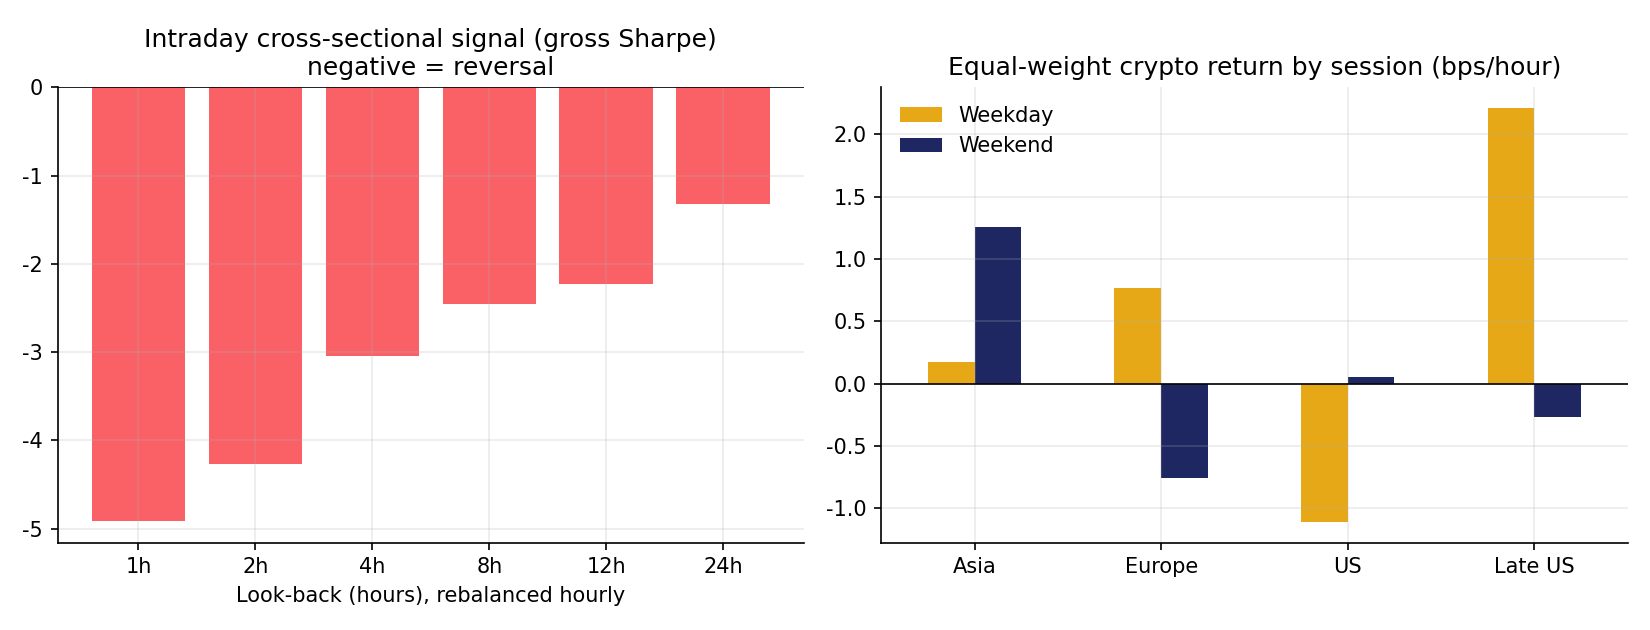

,lookback_hours,Gross Sharpe,Gross Sharpe IS,Gross Sharpe OOS,Gross bps/hour,Turnover/hour,Cost bps/hour @7,Net Sharpe @7,Net Sharpe @20
0,1,-4.911,-5.080,-4.786,-1.126,1.340,9.379,-43.222,-103.317
1,2,-4.267,-5.331,-3.472,-0.979,0.951,6.660,-31.980,-77.155
2,4,-3.049,-4.271,-2.161,-0.699,0.694,4.861,-23.621,-58.467
3,8,-2.459,-3.839,-1.453,-0.564,0.510,3.567,-17.714,-44.364
4,12,-2.226,-3.634,-1.213,-0.519,0.425,2.976,-14.819,-37.140
5,24,-1.326,-1.900,-0.908,-0.312,0.311,2.175,-10.506,-27.064


,Test,kind,Gross bps/day,Gross Sharpe,Gross Sharpe IS,Gross Sharpe OOS,Net Sharpe @7,Net Sharpe @20,t-stat
0,"Pre-US return -> US session (TS, each coin)",Time-series,-4.672,-0.468,-1.341,0.160,-1.869,-4.473,-0.987
1,"Pre-US return -> US session (TS, each coin)",Cross-sectional,0.317,0.100,-0.783,0.678,-4.302,-12.477,0.206
2,Prior-day US session -> today's US session,Time-series,-3.865,-0.365,-1.096,0.136,-1.685,-4.137,-0.825
3,Prior-day US session -> today's US session,Cross-sectional,1.634,0.534,0.399,0.627,-4.043,-12.542,1.165
4,US session -> late-US / overnight,Time-series,0.372,0.067,0.649,-0.403,-2.451,-7.129,0.147
5,US session -> late-US / overnight,Cross-sectional,-1.924,-1.131,-1.595,-0.786,-9.357,-24.636,-2.382


In [8]:
display(Image("figures/C_intraday_sessions.png"))
display(rd("A2_intraday_horizon"))
rd("E_frontrun_us_session")

## 5. New information / activity
Weighting momentum by abnormal dollar volume strengthens short-horizon momentum; low-activity (uninformed) moves show weaker momentum.

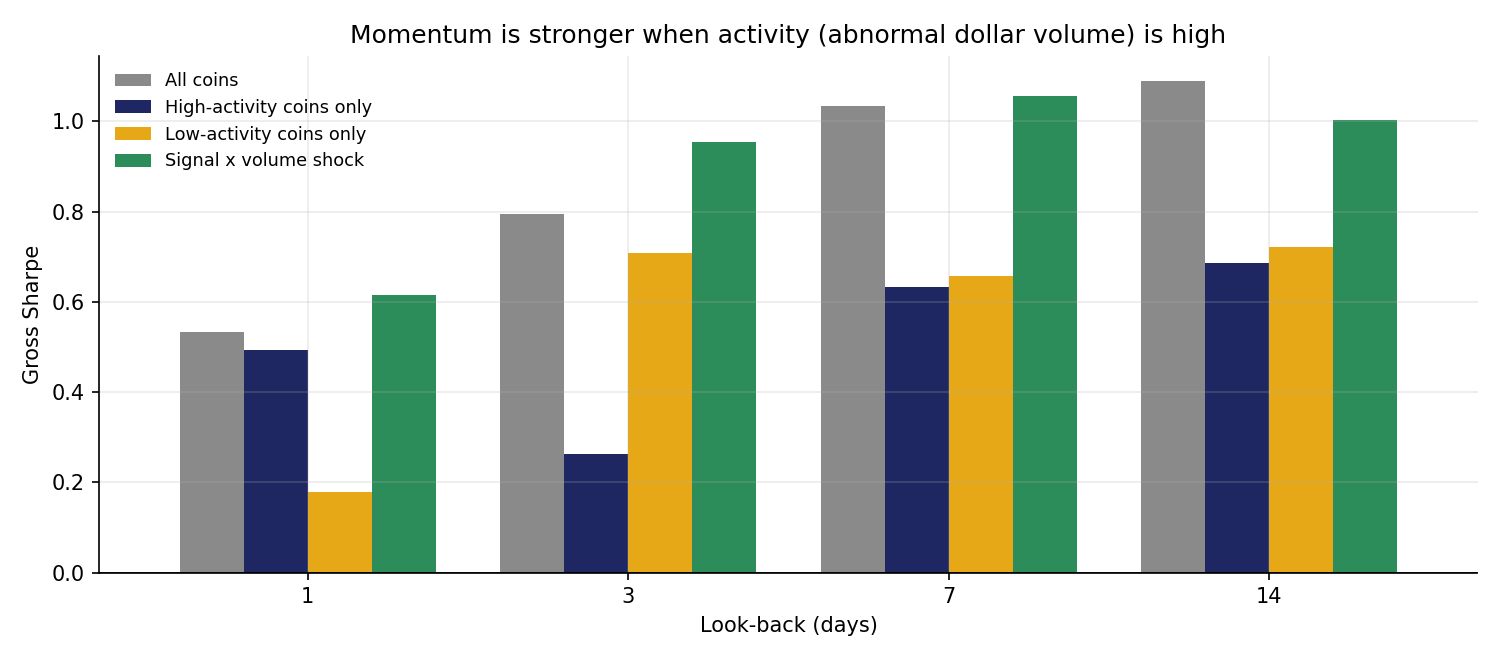

,Strategy,Gross IS,Gross OOS,Gross Full,Net7 Full
0,CS momentum L=1d | All coins,0.405,0.658,0.534,-1.076
1,CS momentum L=1d | High-activity coins only,0.157,0.805,0.493,-0.826
2,CS momentum L=1d | Low-activity coins only,0.608,-0.240,0.178,-1.825
3,CS momentum L=1d | Signal x volume shock,0.207,0.995,0.615,-0.521
4,CS momentum L=3d | All coins,0.953,0.632,0.794,-0.186
5,CS momentum L=3d | High-activity coins only,0.268,0.260,0.263,-0.724
6,CS momentum L=3d | Low-activity coins only,1.264,0.179,0.708,-0.864
7,CS momentum L=3d | Signal x volume shock,0.903,1.006,0.954,0.265
8,CS momentum L=7d | All coins,1.374,0.697,1.033,0.393
9,CS momentum L=7d | High-activity coins only,0.956,0.318,0.632,-0.181


In [9]:
display(Image("figures/B_activity_volume.png"))
rd("B_activity_volume")[["Strategy", "Gross IS", "Gross OOS", "Gross Full", "Net7 Full"]]

## 6. Seasonality
Time-series momentum is far stronger on weekends; crypto gains accrue outside US hours.

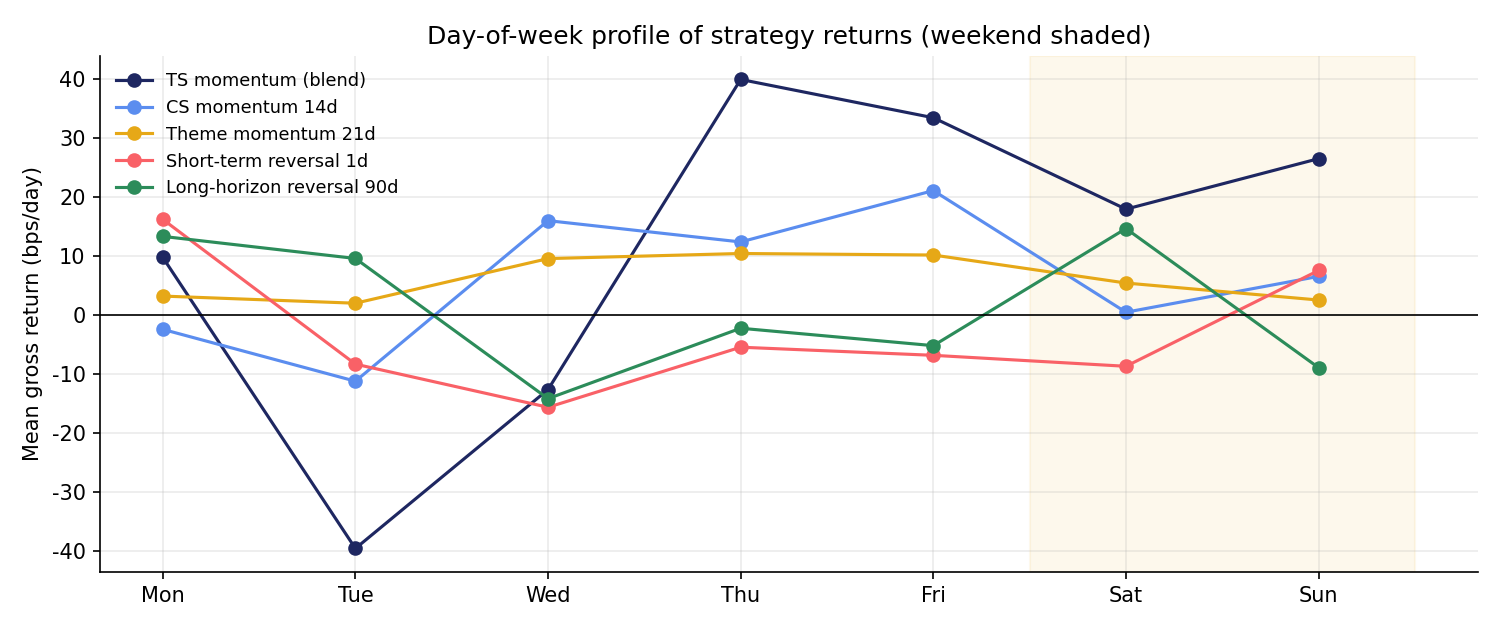

,Strategy,Weekday Sharpe,Weekend Sharpe,Weekday bps/day,Weekend bps/day
0,TS momentum (blend),0.390,1.774,6.214,22.255
1,CS momentum 14d,1.256,0.651,7.172,3.507
2,Theme momentum 21d,1.319,0.803,7.081,3.979
3,Short-term reversal 1d,-0.705,-0.103,-4.024,-0.581
4,Long-horizon reversal 90d,0.045,0.545,0.251,2.866


,Strategy,Gross IS,Gross OOS,Net20 Full,Net7 Full,Turnover
0,TS momentum | All days,0.927,0.504,0.411,0.610,0.228
1,TS momentum | Weekend only (Fri-Sun close),1.319,0.441,0.117,0.598,0.334
2,TS momentum | Weekdays only,0.224,0.287,-0.396,0.025,0.391


,day_type,session,EW mean bps/hour,BTC mean bps/hour,EW vol bps/hour
0,Weekday,Asia (00-08 UTC),0.172,-0.106,76.936
1,Weekday,Europe (08-13 UTC),0.770,1.101,74.125
2,Weekday,Late US (21-24 UTC),2.212,1.345,73.447
3,Weekday,US (13-21 UTC),-1.110,-0.162,94.231
4,Weekend,Asia (00-08 UTC),1.255,-0.061,61.060
5,Weekend,Europe (08-13 UTC),-0.754,0.347,54.899
6,Weekend,Late US (21-24 UTC),-0.265,-0.104,74.002
7,Weekend,US (13-21 UTC),0.050,0.538,67.426


In [10]:
display(Image("figures/C_day_of_week.png"))
display(rd("C_weekday_weekend")[["Strategy", "Weekday Sharpe", "Weekend Sharpe", "Weekday bps/day", "Weekend bps/day"]])
display(rd("C_weekend_momentum")[["Strategy", "Gross IS", "Gross OOS", "Net20 Full", "Net7 Full", "Turnover"]])
rd("C_session_returns")

## 7. Investment themes
Theme momentum was the strongest research-period signal but decayed in the hold-out.

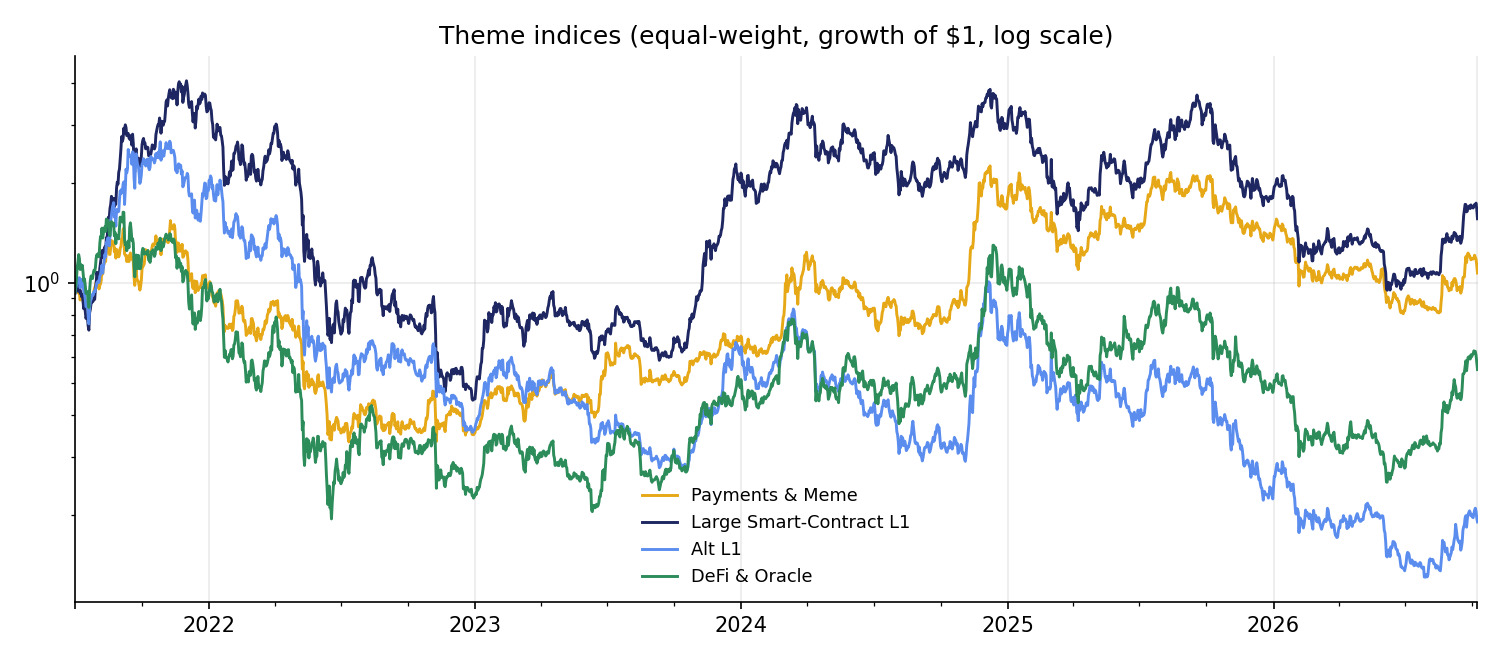

,Strategy,Gross IS,Gross OOS,Net20 Full,Net7 Full,Turnover
0,Theme momentum L=7d H=1d,1.311,0.458,-0.893,0.250,0.461
1,Theme momentum L=7d H=3d,0.921,0.163,-0.723,0.101,0.344
2,Theme momentum L=7d H=7d,1.300,0.415,-0.102,0.525,0.258
3,Theme momentum L=14d H=1d,2.021,0.662,0.150,0.932,0.311
4,Theme momentum L=14d H=3d,1.770,0.294,0.193,0.762,0.230
5,Theme momentum L=14d H=7d,1.726,0.115,0.363,0.761,0.163
6,Theme momentum L=21d H=1d,1.992,0.299,0.212,0.837,0.253
7,Theme momentum L=21d H=3d,1.741,0.234,0.314,0.772,0.188
8,Theme momentum L=21d H=7d,1.506,0.475,0.509,0.838,0.133
9,Theme momentum L=30d H=1d,1.759,0.333,0.234,0.780,0.219


In [11]:
display(Image("figures/D_theme_indices.png"))
rd("D_theme_momentum")[["Strategy", "Gross IS", "Gross OOS", "Net20 Full", "Net7 Full", "Turnover"]]

## 8. Correlation-based reversal
Residuals vs the market trend; residuals vs the coin's own theme revert over 1-2 months; cointegrated pairs are market-neutral but too weak after costs.

,Strategy,Gross IS,Gross OOS,Gross Full,Net20 Full,Net7 Full,Turnover
0,Market-residual reversal L=1d,-0.490,-0.689,-0.594,-5.526,-2.285,1.316
1,Theme-residual reversal L=1d,0.189,-0.078,0.056,-5.544,-1.850,1.324
2,Market-residual reversal L=3d,-0.860,-1.072,-0.964,-3.902,-1.981,0.764
3,Theme-residual reversal L=3d,0.054,0.120,0.087,-3.066,-1.003,0.767
4,Market-residual reversal L=7d,-1.028,-0.987,-1.007,-2.882,-1.660,0.510
5,Theme-residual reversal L=7d,-0.921,-0.061,-0.471,-2.547,-1.193,0.516
6,Market-residual reversal L=30d,-0.978,0.263,-0.361,-1.324,-0.697,0.258
7,Theme-residual reversal L=30d,0.065,1.260,0.675,-0.440,0.286,0.262
8,Market-residual reversal L=60d,-0.265,0.193,-0.037,-0.727,-0.278,0.186
9,Theme-residual reversal L=60d,0.808,0.747,0.777,-0.047,0.489,0.197


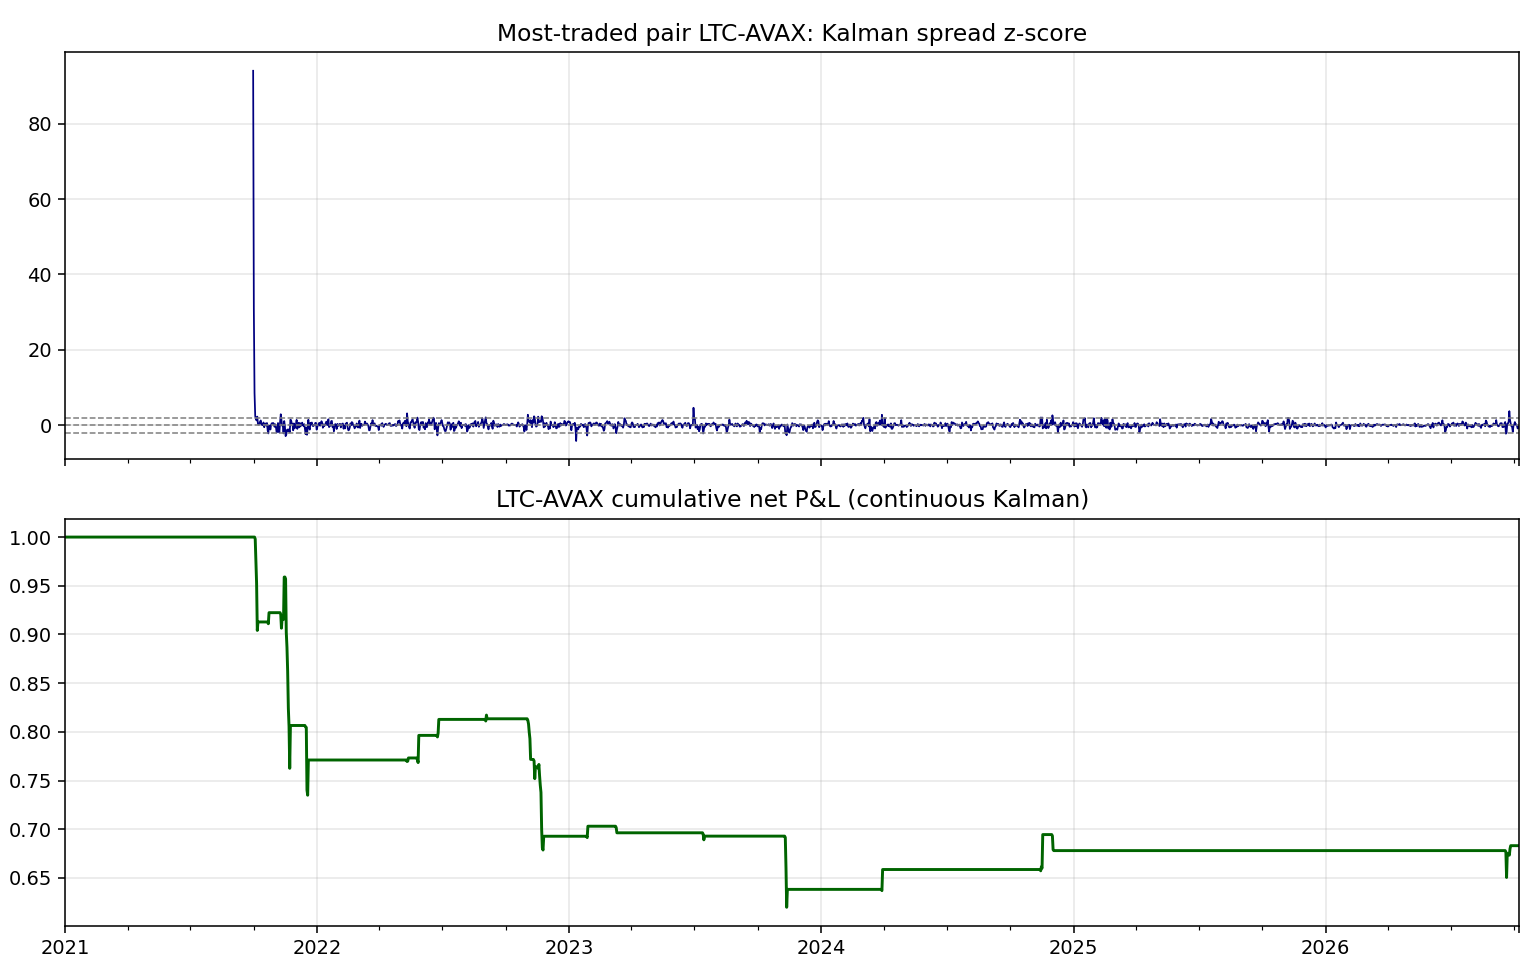

,Unnamed: 0,windows_selected,pct_of_windows
0,LTC-AVAX,17,0.205
1,XLM-ADA,14,0.169
2,COMP-LTC,13,0.157
3,ETH-BTC,13,0.157
4,ATOM-ADA,12,0.145
5,LTC-ADA,12,0.145
6,LTC-LINK,12,0.145
7,XLM-DOGE,11,0.133
8,XLM-LTC,11,0.133
9,LTC-DOGE,11,0.133


In [12]:
display(rd("F_correlation_reversal")[["Strategy", "Gross IS", "Gross OOS", "Gross Full", "Net20 Full", "Net7 Full", "Turnover"]])
display(Image("figures/example_pair.png"))
pd.read_csv("data/pair_frequency.csv").head(10)

## 9. Macro regimes
Reversal does better when volatility and correlation are high; time-series momentum breaks down when implied volatility (DVOL) is high.

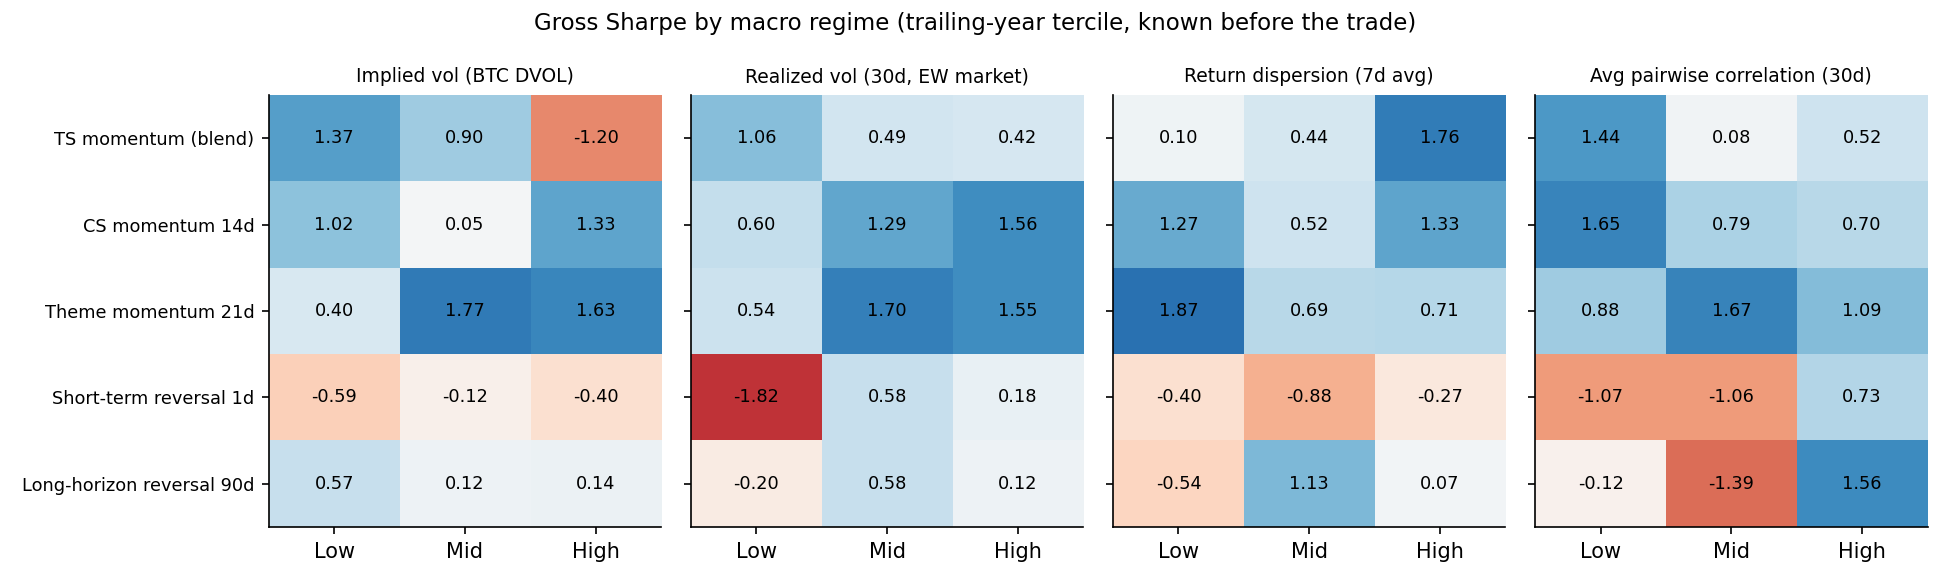

,Strategy,Indicator,Low Sharpe,Mid Sharpe,High Sharpe
0,TS momentum (blend),Implied vol (BTC DVOL),1.367,0.898,-1.196
1,TS momentum (blend),"Realized vol (30d, EW market)",1.064,0.485,0.421
2,TS momentum (blend),Return dispersion (7d avg),0.104,0.440,1.755
3,TS momentum (blend),Avg pairwise correlation (30d),1.438,0.083,0.521
4,CS momentum 14d,Implied vol (BTC DVOL),1.025,0.051,1.326
5,CS momentum 14d,"Realized vol (30d, EW market)",0.603,1.291,1.556
6,CS momentum 14d,Return dispersion (7d avg),1.266,0.518,1.327
7,CS momentum 14d,Avg pairwise correlation (30d),1.647,0.790,0.702
8,Theme momentum 21d,Implied vol (BTC DVOL),0.396,1.772,1.627
9,Theme momentum 21d,"Realized vol (30d, EW market)",0.536,1.701,1.551


In [13]:
display(Image("figures/G_macro_regimes.png"))
rd("G_macro_regimes")[["Strategy", "Indicator", "Low Sharpe", "Mid Sharpe", "High Sharpe"]]

## 10. Strategy selection and execution
All choices use the research period only. The momentum book is an ensemble of the best time-series, theme and cross-sectional variants.

{
  "momentum_components": [
    "TS momentum blend H=1 + DVOL filter",
    "Theme momentum L=14 H=7",
    "CS momentum L=14 H=7"
  ],
  "reversal_selected": "Long-horizon reversal L=60 skip=14 H=14",
  "execution_selected": {
    "Momentum": "No-trade band 2%",
    "Reversal": "Hold 3d (overlapping)"
  },
  "weighting_selected": "Mean-variance (shrunk)"
}


,Strategy,family,Selection IS,Net20 OOS,Net7 OOS,Turnover
0,Theme momentum L=14 H=7,Momentum,1.200,-0.612,-0.140,0.163
1,Theme momentum L=21 H=3,Momentum,1.128,-0.581,-0.053,0.188
2,Theme momentum L=30 H=3,Momentum,1.122,-0.863,-0.407,0.157
3,Theme momentum L=21 H=1,Momentum,1.119,-0.772,-0.082,0.253
4,Theme momentum L=21 H=7,Momentum,1.060,-0.110,0.270,0.133
5,Theme momentum L=14 H=3,Momentum,1.017,-0.734,-0.068,0.230
33,Long-horizon reversal L=60 skip=14 H=14,Reversal,0.902,0.839,0.978,0.062
34,Long-horizon reversal L=60 skip=14 H=7,Reversal,0.810,0.627,0.821,0.084
35,Cointegration pairs (Kalman),Reversal,0.377,-0.368,-0.135,0.029
36,Long-horizon reversal L=60 skip=0 H=14,Reversal,0.202,0.641,0.770,0.054


,Book,Execution,Turnover,Sharpe IS @exec cost,Sharpe gross,Sharpe limit 7bps,Sharpe market 20bps,Cost drag/yr @20
0,Momentum,Daily rebalance,0.237,1.222,1.258,1.080,0.749,0.173
1,Momentum,Hold 3d (overlapping),0.172,1.101,0.951,0.818,0.571,0.126
2,Momentum,Hold 7d (overlapping),0.137,0.804,0.685,0.580,0.386,0.100
3,Momentum,No-trade band 2%,0.197,1.397,1.259,1.110,0.834,0.144
4,Momentum,No-trade band 5%,0.137,1.087,0.950,0.838,0.630,0.100
5,Reversal,Daily rebalance,0.062,0.902,1.021,0.943,0.799,0.045
6,Reversal,Hold 3d (overlapping),0.059,0.918,1.037,0.963,0.825,0.043
7,Reversal,Hold 7d (overlapping),0.056,0.884,1.041,0.970,0.840,0.041
8,Reversal,No-trade band 2%,0.048,0.839,0.996,0.934,0.820,0.035
9,Reversal,No-trade band 5%,0.037,0.755,0.916,0.868,0.779,0.027


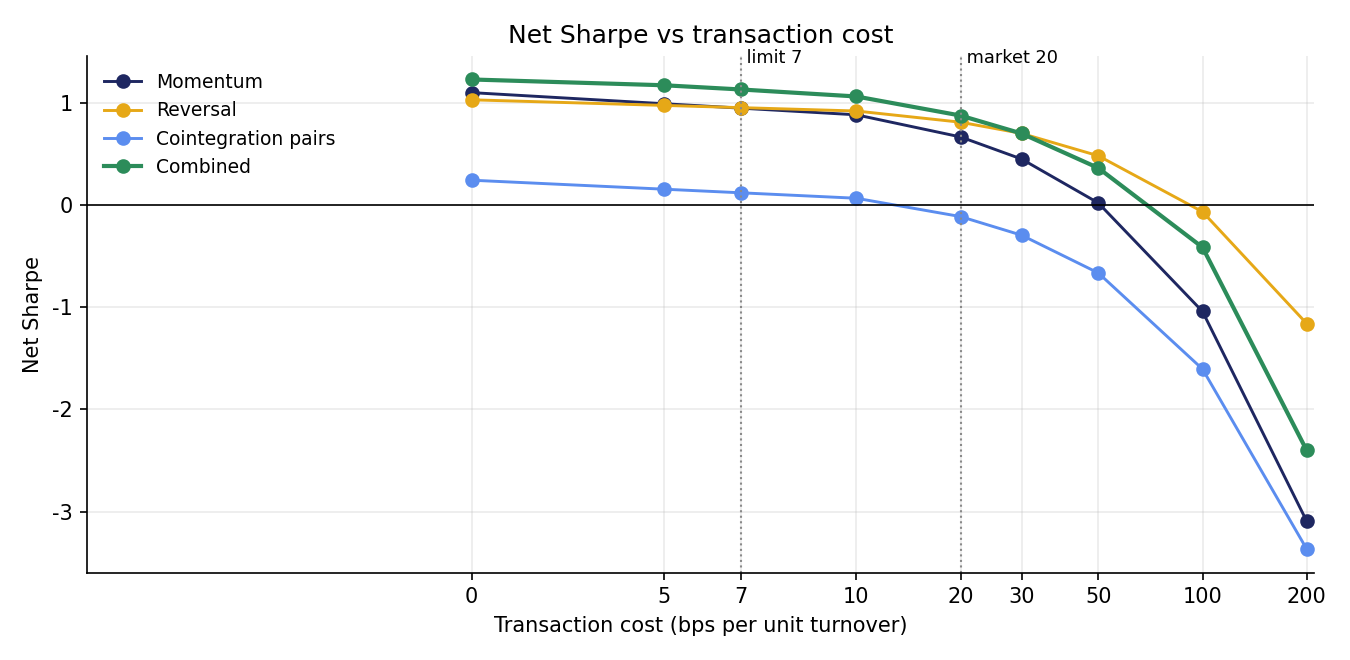

,cost_bps,Momentum,Reversal,Cointegration pairs,Combined
0,0,1.102,1.032,0.244,1.230
1,5,0.993,0.977,0.156,1.174
2,7,0.950,0.955,0.121,1.133
3,10,0.885,0.922,0.068,1.064
4,20,0.668,0.812,-0.112,0.877
5,30,0.452,0.703,-0.294,0.702
6,50,0.022,0.483,-0.664,0.364
7,100,-1.041,-0.065,-1.605,-0.413
8,200,-3.094,-1.160,-3.367,-2.402


In [14]:
print(json.dumps({k: S[k] for k in ["momentum_components", "reversal_selected", "execution_selected", "weighting_selected"]}, indent=2))
sel = rd("H_candidate_selection")
display(sel.groupby("family").head(6)[["Strategy", "family", "Selection IS", "Net20 OOS", "Net7 OOS", "Turnover"]])
display(rd("H_execution_variants"))
display(Image("figures/H_cost_sweep.png"))
rd("H_cost_sweep")

## 11. Weighting

,Momentum ensemble,Reversal,TS momentum blend,Theme momentum,CS momentum,Cointegration pairs,BTC
Unnamed: 0,,,,,,,
Momentum ensemble,1.000,0.082,0.823,0.590,0.667,-0.074,-0.174
Reversal,0.082,1.000,0.075,0.030,0.038,-0.040,0.015
TS momentum blend,0.823,0.075,1.000,0.113,0.202,-0.055,-0.223
Theme momentum,0.590,0.030,0.113,1.000,0.711,-0.049,-0.041
CS momentum,0.667,0.038,0.202,0.711,1.000,-0.074,-0.026
Cointegration pairs,-0.074,-0.040,-0.055,-0.049,-0.074,1.000,0.035
BTC,-0.174,0.015,-0.223,-0.041,-0.026,0.035,1.000


,Method,Avg weight Momentum,Avg weight Reversal,Sharpe,Sharpe IS,Sharpe OOS
0,Equal weight,0.500,0.500,1.016,1.437,0.699
1,Inverse volatility,0.376,0.624,1.096,1.540,0.805
2,Risk parity (ERC),0.376,0.624,1.096,1.540,0.805
3,Mean-variance (shrunk),0.327,0.673,1.025,1.714,0.549


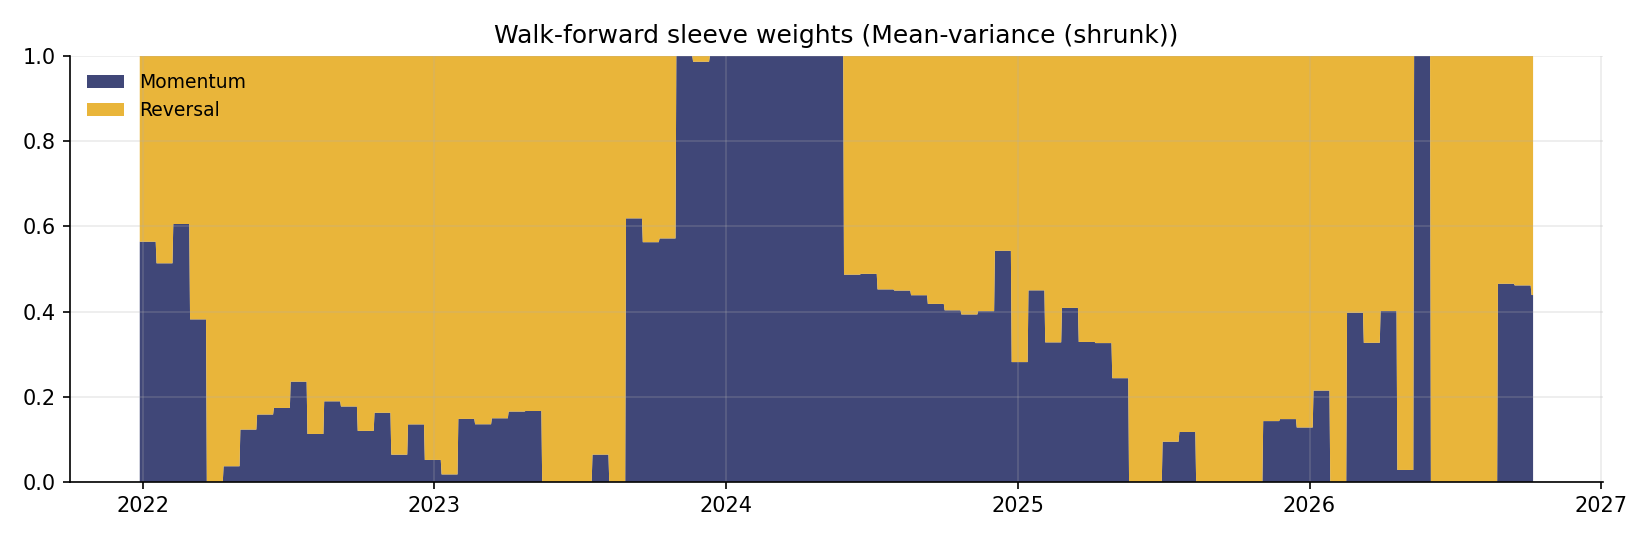

,Momentum sleeve,Momentum Sharpe IS,Momentum Sharpe OOS,Combined Sharpe IS,Combined Sharpe OOS,Combined Sharpe Full
0,Final: momentum ensemble (best TS + theme + CS),1.189,0.220,1.714,0.549,1.025
1,Single IS-best momentum (Theme momentum L=14 H=7),1.223,-0.612,1.836,0.093,0.808
2,TS momentum only (TS momentum blend H=1 + DVOL...,0.745,0.669,1.366,0.676,0.900


In [15]:
display(rd("I_sleeve_correlation").set_index("Unnamed: 0"))
display(rd("I_weighting_methods"))
display(Image("figures/I_sleeve_weights.png"))
rd("I_selection_robustness")

## 12. Performance evaluation
Returns, volatility, Sharpe, max drawdown and alpha / beta (vs Bitcoin), for the full backtest, research period and hold-out.

In [16]:
cols = ["Ann.Return", "Ann.Vol", "Sharpe", "MaxDD", "Alpha", "Beta", "Alpha t"]
for name, f in [("Full backtest", "J_performance_full"), ("Research period", "J_performance_is"), ("Hold-out", "J_performance_oos")]:
    print(name); display(rd(f).set_index("Strategy")[cols])

Full backtest


,Ann.Return,Ann.Vol,Sharpe,MaxDD,Alpha,Beta,Alpha t
Strategy,,,,,,,
Momentum ensemble (net 20bps market),0.223,0.333,0.668,-0.311,0.252,-0.130,1.681
Momentum ensemble (net 7bps limit),0.316,0.333,0.950,-0.251,0.346,-0.130,2.310
Reversal (net 7bps limit),0.187,0.196,0.955,-0.337,0.187,0.002,2.009
Reversal (net 20bps market),0.159,0.196,0.812,-0.356,0.159,0.002,1.708
Cointegration pairs (net 20bps),-0.007,0.066,-0.112,-0.129,-0.009,0.005,-0.322
Combined portfolio,0.202,0.197,1.025,-0.281,0.206,-0.018,2.187
Combined portfolio (all at 20bps market),0.173,0.198,0.877,-0.286,0.178,-0.020,1.883
Equal-weight crypto (B&H),0.093,0.701,0.133,-0.774,-0.174,1.166,-0.996
Buy & Hold BTC,0.229,0.508,0.450,-0.670,-0.000,1.000,-1.356


Research period


,Ann.Return,Ann.Vol,Sharpe,MaxDD,Alpha,Beta,Alpha t
Strategy,,,,,,,
Momentum ensemble (net 20bps market),0.437,0.367,1.189,-0.280,0.445,-0.138,1.760
Momentum ensemble (net 7bps limit),0.527,0.367,1.439,-0.251,0.536,-0.137,2.129
Reversal (net 7bps limit),0.156,0.177,0.886,-0.261,0.156,0.002,1.239
Reversal (net 20bps market),0.128,0.177,0.727,-0.264,0.128,0.002,1.017
Cointegration pairs (net 20bps),0.013,0.072,0.187,-0.060,0.013,0.011,0.291
Combined portfolio,0.329,0.192,1.714,-0.126,0.330,-0.021,2.422
Combined portfolio (all at 20bps market),0.309,0.194,1.592,-0.135,0.310,-0.024,2.251
Equal-weight crypto (B&H),-0.067,0.727,-0.092,-0.774,-0.138,1.141,-0.520
Buy & Hold BTC,0.062,0.551,0.113,-0.670,0.000,1.000,3.652


Hold-out


,Ann.Return,Ann.Vol,Sharpe,MaxDD,Alpha,Beta,Alpha t
Strategy,,,,,,,
Momentum ensemble (net 20bps market),0.068,0.306,0.220,-0.267,0.110,-0.122,0.614
Momentum ensemble (net 7bps limit),0.163,0.306,0.532,-0.212,0.205,-0.122,1.147
Reversal (net 7bps limit),0.210,0.210,1.002,-0.220,0.209,0.002,1.588
Reversal (net 20bps market),0.182,0.210,0.868,-0.238,0.181,0.002,1.376
Cointegration pairs (net 20bps),-0.022,0.061,-0.368,-0.117,-0.022,-0.000,-0.695
Combined portfolio,0.111,0.201,0.549,-0.235,0.116,-0.014,0.900
Combined portfolio (all at 20bps market),0.075,0.200,0.376,-0.240,0.081,-0.016,0.631
Equal-weight crypto (B&H),0.209,0.683,0.306,-0.752,-0.208,1.191,-0.899
Buy & Hold BTC,0.349,0.474,0.737,-0.531,0.000,1.000,0.329


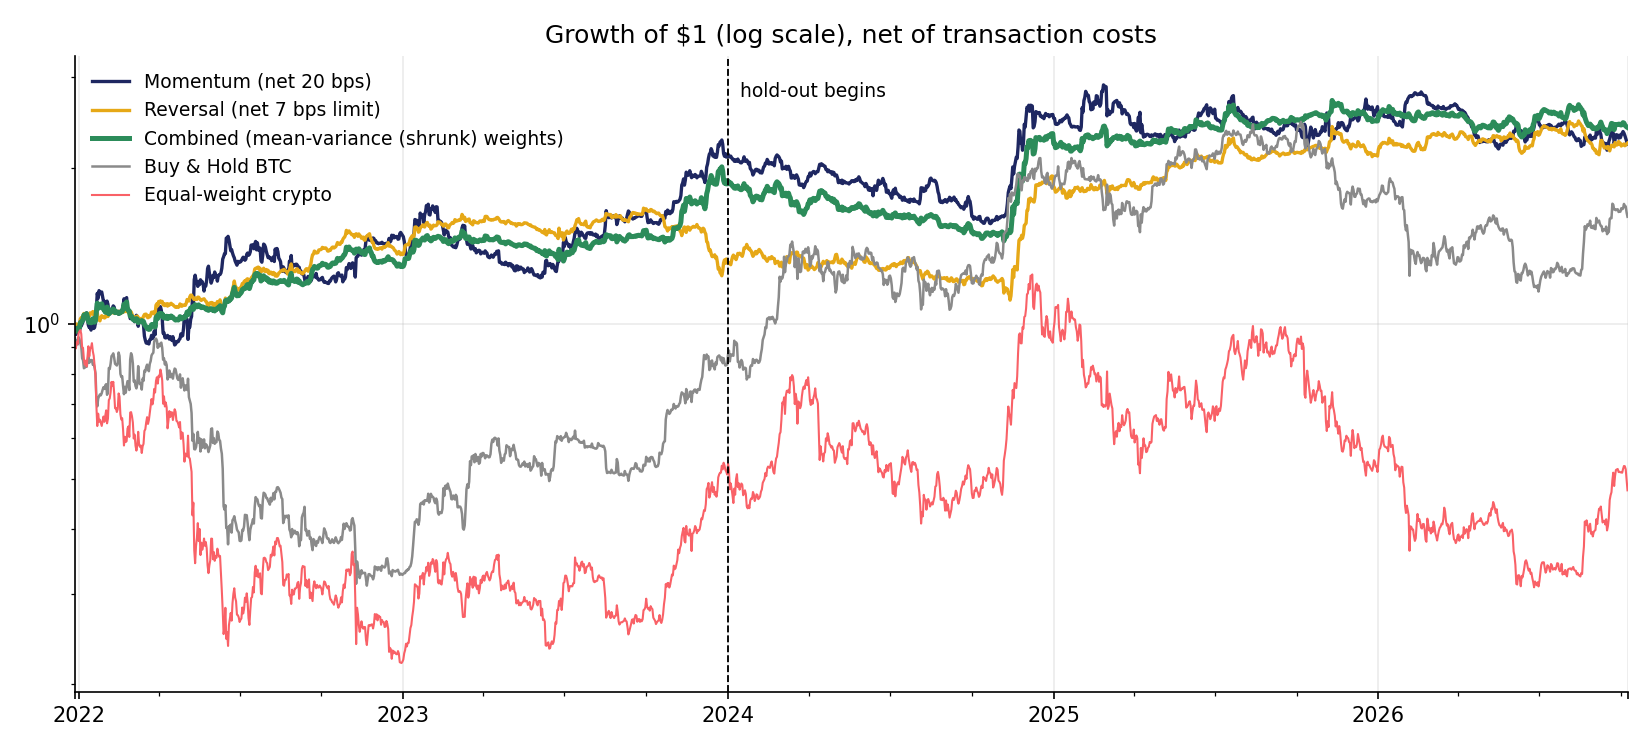

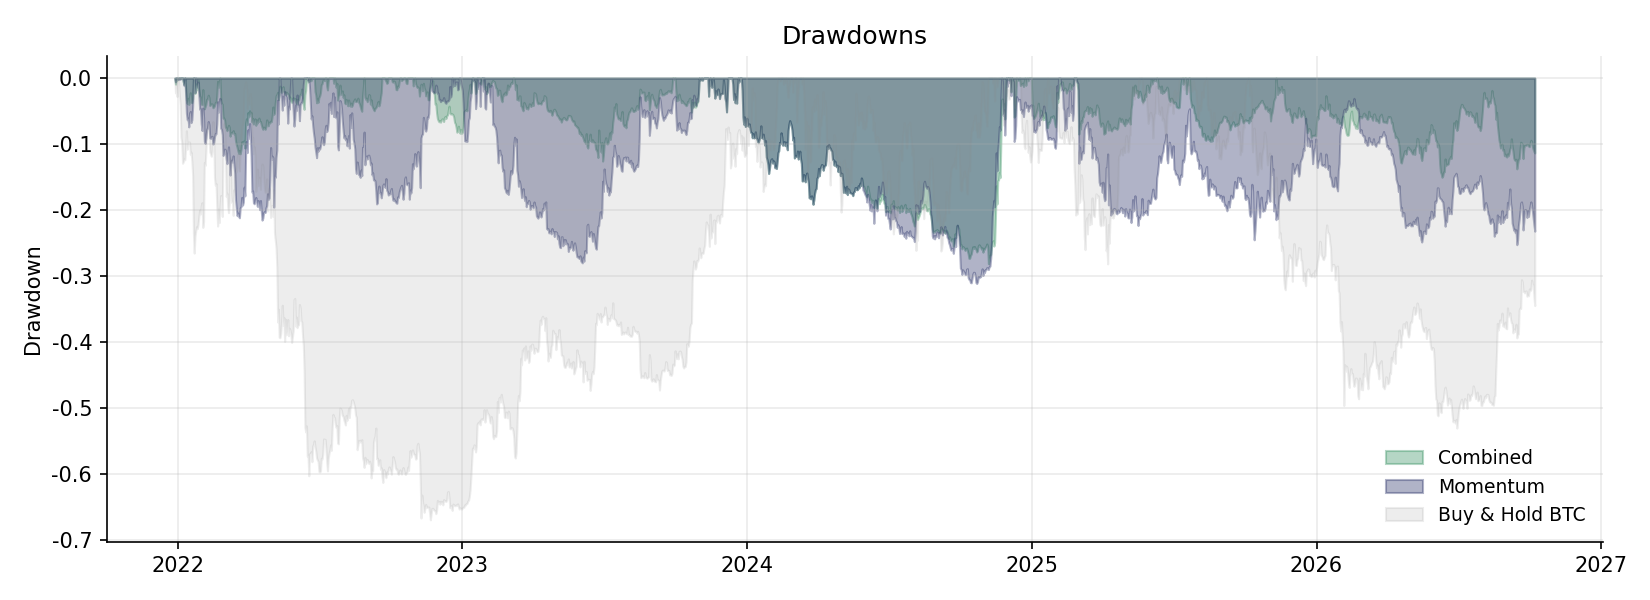

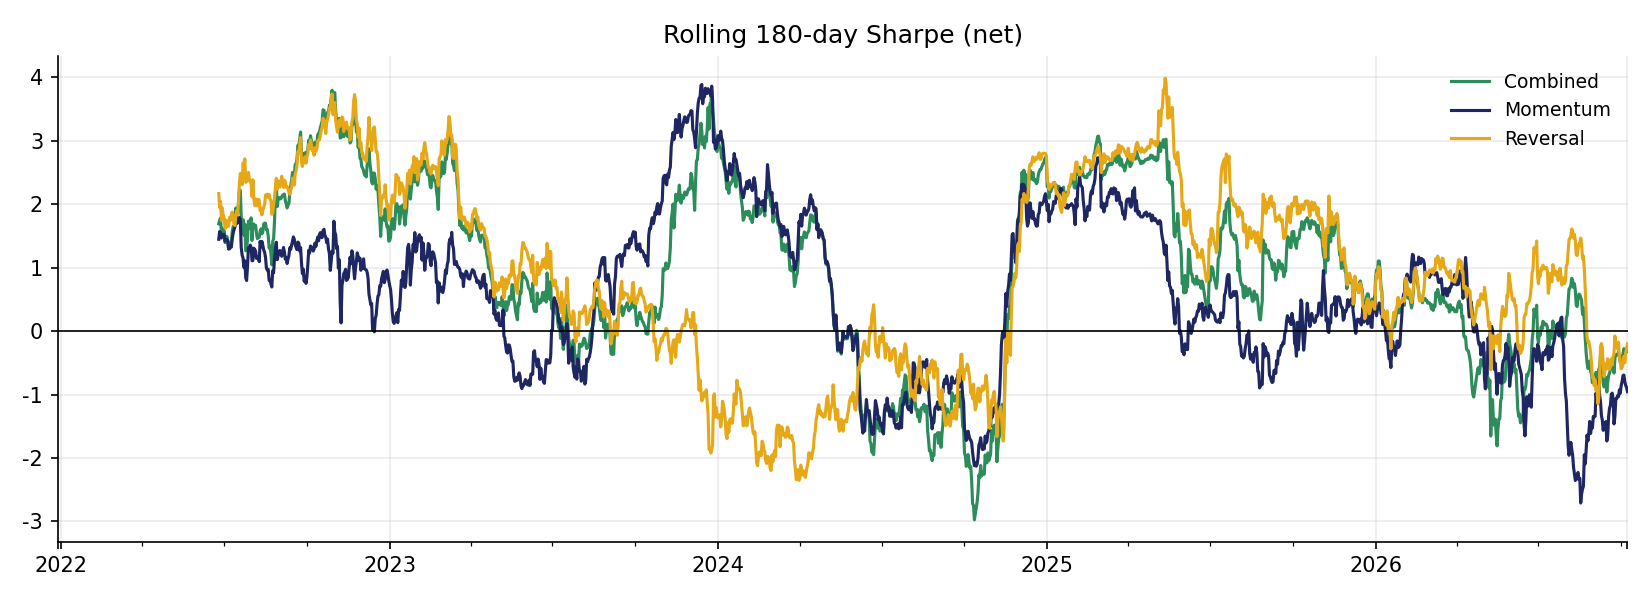

In [17]:
display(Image("figures/J_equity_curves.png"))
display(Image("figures/J_drawdowns.png"))
display(Image("figures/J_rolling_sharpe.png"))

## 13. Conclusion
* Crypto shows **momentum at horizons of days to weeks** and **reversal at the extremes** (within the hour and over
  about two months). The brief's conditioning variables - activity, seasonality, themes and macro - are all visible.
* **Execution decides** which edges survive: no-trade bands, slow signals and limit orders matter as much as the signal.
* **Combining** an uncorrelated momentum ensemble and reversal book gives a market-neutral portfolio with a higher
  Sharpe and smaller drawdown than either part.
* **Expect decay:** the hold-out Sharpe is lower than the research-period Sharpe; live paper trading is the next step.
